# LAB 07 — Transformer Architecture

## 0. Setup

In [1]:
# NOTE: pandas phai duoc import TRUOC torch (Windows: import pandas sau torch gay heap-corruption 0xC0000374).
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
import sys, os, json, time, math, random, warnings
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

LAB07 = Path.cwd()
LAB05 = LAB07.parent / "Lab05"
assert (LAB07 / "transformer_block.py").exists(), "chay notebook voi cwd = Lab07/"
sys.path.insert(0, str(LAB07)); sys.path.insert(0, str(LAB05))
import sequence_models as sm                      # LAB 05: split, vocab, tokenizer, train/eval loops, LSTM baseline
from positional_encoding import sinusoidal_positional_encoding, PositionalEncoding
import positional_encoding as pe_mod
from transformer_block import MultiHeadSelfAttention, TransformerBlock, TransformerClassifier
import transformer_block as tb_mod

SEED, SEEDS = 42, (42, 43, 44)
D_MODEL, N_HEADS, D_FF, N_LAYERS, DROPOUT = 128, 4, 256, 2, 0.1
BATCH, LR, EPOCHS, MAX_LEN = 128, 1e-3, 5, 128      # chung cho LSTM va Transformer
if os.environ.get("LAB07_FAST") == "1":              # co debug: 1 epoch, 1 seed (mac dinh TAT; ket qua nop chay voi co nay tat)
    SEEDS, EPOCHS = (42,), 1
dev = sm.get_device()
sm.set_seed(SEED)
print("torch", torch.__version__, "| device", dev, "|", torch.cuda.get_device_name(0) if dev.type == "cuda" else "cpu")

RESULTS = []
def jd(d): return json.dumps(d, ensure_ascii=False, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
def add_result(experiment, config, params=None, train_time_s=None, metrics=None, **extra):
    m = metrics or {}
    RESULTS.append(dict(experiment=experiment, config=config, params=params,
                        train_time_s=None if train_time_s is None else round(float(train_time_s), 2),
                        accuracy=m.get("accuracy"), precision=m.get("precision"), recall=m.get("recall"), f1=m.get("f1"),
                        extra=jd(extra)))

torch 2.12.0+cu126 | device cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 1. Dữ liệu — đúng split/vocab của LAB 05

In [2]:
raw_train, raw_test, source = sm.load_imdb_dataset(LAB05 / "data")
train_df, val_df, test_df, split_report = sm.make_splits(raw_train, raw_test)          # seed 42, y het LAB 05
vocab = sm.Vocabulary.from_texts(train_df["text"], max_size=sm.MAX_VOCAB_SIZE)       # chi tu train
assert (len(train_df), len(val_df), len(test_df), len(vocab)) == (31879, 7904, 10000, 30000), "khong khop LAB 05"
print(source); print("train/val/test =", len(train_df), len(val_df), len(test_df), "| vocab", len(vocab), "| dup report", split_report)
enc = {n: [sm.encode_text(t, vocab) for t in df["text"]] for n, df in (("train", train_df), ("val", val_df), ("test", test_df))}
labels = {n: df["label"].map(int).tolist() for n, df in (("train", train_df), ("val", val_df), ("test", test_df))}
tok_len = np.array([len(s) for s in enc["train"]])
print("train token length: median %d mean %.1f P90 %d max %d" % (np.median(tok_len), tok_len.mean(), np.percentile(tok_len, 90), tok_len.max()))
print("label balance train:", np.bincount(labels["train"]), "test:", np.bincount(labels["test"]))

local CSV partitions: D:\Study\Semester 7\NLP\Lab05\data
train/val/test = 31879 7904 10000 | vocab 30000 | dup report {'removed_train_vs_test': 121, 'removed_validation_vs_test': 23, 'removed_validation_vs_train': 73, 'cross_split_duplicates_after_cleaning': 0}


train token length: median 176 mean 234.3 P90 453 max 2493
label balance train: [15911 15968] test: [5000 5000]


## 2. Unit test (PE, shape, mask) + so sánh số học với `nn.TransformerEncoderLayer`

In [3]:
pe_mod.run_self_tests()
print()
tb_mod.run_self_tests()          # in shape tung buoc B=8,T=100,d_model=128,h=4

PE d=4, pos=0,1,2:
[[ 0.       1.       0.       1.     ]
 [ 0.84147  0.5403   0.01     0.99995]
 [ 0.9093  -0.41615  0.02     0.9998 ]]
positional_encoding tests: OK

B=8 T=100 d_model=128 n_heads=4 d_k=32
  X                      (8, 100, 128)
  Q                      (8, 4, 100, 32)
  K                      (8, 4, 100, 32)
  V                      (8, 4, 100, 32)
  scores QK^T/sqrt(dk)   (8, 4, 100, 100)
  attn weights           (8, 4, 100, 100)
  head outputs           (8, 4, 100, 32)
  concat heads           (8, 100, 128)
  after W^O              (8, 100, 128)
  Add&Norm 1             (8, 100, 128)
  FFN hidden             (8, 100, 512)
  FFN out                (8, 100, 128)
  output                 (8, 100, 128)
transformer_block tests: OK


In [4]:
# So sanh voi nn.TransformerEncoderLayer (post-norm) CHI Ở PHẦN TEST — cùng trọng số, dropout=0.
torch.manual_seed(0)
d, h, dff, B, T = 128, 4, 256, 4, 20
mine = TransformerBlock(d, h, dff, dropout=0.0).eval()
ref = nn.TransformerEncoderLayer(d, h, dim_feedforward=dff, dropout=0.0, activation="relu", batch_first=True, norm_first=False).eval()
with torch.no_grad():
    ref.self_attn.in_proj_weight.copy_(torch.cat([mine.attn.w_q.weight, mine.attn.w_k.weight, mine.attn.w_v.weight]))
    ref.self_attn.in_proj_bias.copy_(torch.cat([mine.attn.w_q.bias, mine.attn.w_k.bias, mine.attn.w_v.bias]))
    ref.self_attn.out_proj.weight.copy_(mine.attn.w_o.weight); ref.self_attn.out_proj.bias.copy_(mine.attn.w_o.bias)
    ref.linear1.weight.copy_(mine.ffn[0].weight); ref.linear1.bias.copy_(mine.ffn[0].bias)
    ref.linear2.weight.copy_(mine.ffn[3].weight); ref.linear2.bias.copy_(mine.ffn[3].bias)
    ref.norm1.load_state_dict(mine.norm1.state_dict()); ref.norm2.load_state_dict(mine.norm2.state_dict())
    x = torch.randn(B, T, d)
    pad = torch.zeros(B, T, dtype=torch.bool); pad[0, 14:] = True; pad[2, 9:] = True
    diff_nomask = (mine(x) - ref(x)).abs().max().item()
    o_m, o_r = mine(x, pad), ref(x, src_key_padding_mask=pad)
    diff_mask = (o_m - o_r).abs()[~pad].max().item()
print(f"max|mine - nn.TransformerEncoderLayer|  no mask: {diff_nomask:.2e} | padding mask (valid positions): {diff_mask:.2e}")
assert diff_nomask < 1e-5 and diff_mask < 1e-5
COMPARE_TORCH = dict(no_mask=diff_nomask, with_mask=diff_mask)
n_params_block = sum(p.numel() for p in mine.parameters())
print("TransformerBlock params (d=128,h=4,d_ff=256):", n_params_block)
print({n: p.numel() for n, p in mine.named_parameters()})
add_result("unit_test", "block_vs_nn.TransformerEncoderLayer", n_params_block, None, None, **COMPARE_TORCH)

max|mine - nn.TransformerEncoderLayer|  no mask: 4.77e-07 | padding mask (valid positions): 7.15e-07
TransformerBlock params (d=128,h=4,d_ff=256): 132480
{'attn.w_q.weight': 16384, 'attn.w_q.bias': 128, 'attn.w_k.weight': 16384, 'attn.w_k.bias': 128, 'attn.w_v.weight': 16384, 'attn.w_v.bias': 128, 'attn.w_o.weight': 16384, 'attn.w_o.bias': 128, 'norm1.weight': 128, 'norm1.bias': 128, 'ffn.0.weight': 32768, 'ffn.0.bias': 256, 'ffn.3.weight': 32768, 'ffn.3.bias': 128, 'norm2.weight': 128, 'norm2.bias': 128}


### Trả lời câu hỏi: Q, K, V, attention scores và output của block có shape như thế nào (B=8, T=100, d_model=128, n_heads=4)? Block tự viết có đúng không?
B=8, T=100, d_model=128, n_heads=4 → d_k = 128/4 = 32.

| bước | shape |
|---|---|
| X | (8, 100, 128) |
| Q, K, V (sau split heads) | (8, 4, 100, 32) |
| scores = QKᵀ/√d_k, attention weights | (8, 4, 100, 100) |
| head outputs = A·V | (8, 4, 100, 32) |
| concat heads, sau W^O | (8, 100, 128) |
| Add&Norm 1 | (8, 100, 128) |
| FFN hidden / FFN out (test dùng d_ff = 512) | (8, 100, 512) / (8, 100, 128) |
| output | (8, 100, 128) |

Ma trận attention là **T×T** vì mỗi trong T query chấm với mỗi trong T key. So với `nn.TransformerEncoderLayer` (post-norm, cùng trọng số, dropout 0): sai khác tối đa **4.77e-07** (không mask), **7.15e-07** (padding mask, vị trí hợp lệ) → block tự viết đúng.

## 3. Tính toán tay — kiểm chứng bằng numpy/torch

Đề **không cho số cụ thể** cho X, W: dưới đây là giá trị tự chọn (ghi rõ trong `calculations.md`).

In [5]:
np.set_printoptions(precision=4, suppress=True)
# --- Muc 6: mot head, X in R^{3x4}, d_k = 2 (so lieu TU CHON) ---
X  = np.array([[1,0,1,0],[0,2,0,1],[1,1,1,1]], float)
WQ = np.array([[1,0],[0,1],[1,0],[0,1]], float)
WK = np.array([[0,1],[1,0],[0,1],[1,0]], float)
WV = np.array([[1,0],[0,1],[0,1],[1,0]], float)
Q, K, V = X @ WQ, X @ WK, X @ WV
S = Q @ K.T / np.sqrt(2)
A = np.exp(S - S.max(1, keepdims=True)); A /= A.sum(1, keepdims=True)
Z = A @ V
for n, m in (("Q", Q), ("K", K), ("V", V), ("S=QK^T/sqrt(2)", S), ("A=softmax(S)", A), ("Z=AV", Z)): print(n, m.shape, "\n", m)
print("row sums of A:", A.sum(1))

# --- Muc 7: 2 head, moi head d=2 -> concat (3x4) -> W^O ---
WQ2, WK2, WV2 = WQ[:, ::-1].copy(), WK[:, ::-1].copy(), WV[:, ::-1].copy()          # head 2: projection khac
def head(wq, wk, wv):
    q, k, v = X @ wq, X @ wk, X @ wv; s = q @ k.T / np.sqrt(2); a = np.exp(s - s.max(1, keepdims=True)); a /= a.sum(1, keepdims=True); return a @ v
h1, h2 = head(WQ, WK, WV), head(WQ2, WK2, WV2)
cat = np.concatenate([h1, h2], axis=1)
WO = np.array([[1,0,0,1],[0,1,1,0],[1,1,0,0],[0,0,1,1]], float)
out = cat @ WO
print("head1\n", h1, "\nhead2\n", h2, "\nconcat (3x4)\n", cat, "\nconcat @ W^O (3x4)\n", out)
print("concat @ W^O == h1 @ W^O[:2] + h2 @ W^O[2:] :", np.allclose(out, h1 @ WO[:2] + h2 @ WO[2:]))

# --- Muc 14: FFN. W2, b2 khong cho -> tu chon ---
x = np.array([1., 2.]); W1 = np.eye(2); b1 = np.array([0., -1.]); W2 = np.array([[1., -1.], [2., 0.]]); b2 = np.array([0., 1.])
pre = W1 @ x + b1; hh = np.maximum(pre, 0); y = W2 @ hh + b2
print("W1x+b1 =", pre, "| h = ReLU =", hh, "| y = W2 h + b2 =", y)
CALC = dict(Z=Z.round(4).tolist(), A=A.round(4).tolist(), concat_WO=out.round(4).tolist(), ffn_h=hh.tolist(), ffn_y=y.tolist())
add_result("calc", "mục 6/7/14 (X,W tự chọn)", **CALC)

Q (3, 2) 
 [[2. 0.]
 [0. 3.]
 [2. 2.]]
K (3, 2) 
 [[0. 2.]
 [3. 0.]
 [2. 2.]]
V (3, 2) 
 [[1. 1.]
 [1. 2.]
 [2. 2.]]
S=QK^T/sqrt(2) (3, 3) 
 [[0.     4.2426 2.8284]
 [4.2426 0.     4.2426]
 [2.8284 4.2426 5.6569]]
A=softmax(S) (3, 3) 
 [[0.0114 0.7952 0.1933]
 [0.4964 0.0071 0.4964]
 [0.0454 0.1867 0.7679]]
Z=AV (3, 2) 
 [[1.1933 1.9886]
 [1.4964 1.5036]
 [1.7679 1.9546]]
row sums of A: [1. 1. 1.]
head1
 [[1.1933 1.9886]
 [1.4964 1.5036]
 [1.7679 1.9546]] 
head2
 [[1.9886 1.1933]
 [1.5036 1.4964]
 [1.9546 1.7679]] 
concat (3x4)
 [[1.1933 1.9886 1.9886 1.1933]
 [1.4964 1.5036 1.5036 1.4964]
 [1.7679 1.9546 1.9546 1.7679]] 
concat @ W^O (3x4)
 [[3.1819 3.9771 3.1819 2.3867]
 [3.     3.0071 3.     2.9929]
 [3.7225 3.9092 3.7225 3.5358]]
concat @ W^O == h1 @ W^O[:2] + h2 @ W^O[2:] : True
W1x+b1 = [1. 1.] | h = ReLU = [1. 1.] | y = W2 h + b2 = [0. 3.]


### Trả lời câu hỏi: Một attention head khác attention của LAB 06 ở điểm nào?
Một head chỉ là attention của LAB 06 với Q, K, V lấy từ **ba ma trận chiếu** (W_Q, W_K, W_V). Mỗi hàng A có tổng 1 (`row sums = [1,1,1]`); Z = AV = [[1.1933, 1.9886],[1.4964, 1.5036],[1.7679, 1.9546]]. (X, W do tôi tự chọn vì đề không cho số.)

### Trả lời câu hỏi: Vì sao cần concatenation trước khi áp dụng W^O?
(1) Concat đưa các head về một tensor T×(h·d_k) = T×d_model, và W^O chiếu về đúng d_model để cộng residual và đưa vào block sau. (2) Output cho thấy `concat·W^O == head₁·W^O[:2] + head₂·W^O[2:]` (`True`): W^O là nơi thông tin của các head được **trộn và gán trọng số học được**; trước W^O mỗi head chỉ nhìn subspace d_k riêng. (Head 2 trong ví dụ là bản đảo cột của head 1 nên chỉ minh hoạ đại số, không minh hoạ đa dạng pattern.)

### Trả lời câu hỏi: FFN có phải một cơ chế attention khác không?
Không. h = ReLU([1,1]) = [1,1]; với W₂ = [[1,−1],[2,0]], b₂ = [0,1] (tự chọn) → y = [0, 3]. FFN chỉ biến đổi phi tuyến **trên từng vị trí**, không trộn token với nhau; việc trộn token là của attention.

In [6]:
# --- Residual: F(x) vs x + F(x). Gradient d out / d x qua L lop, F(x)=tanh(Wx), W ~ N(0, (0.5^2)/d) ---
torch.manual_seed(0)
dd = 64
Ws = [torch.randn(dd, dd) * (0.5 / math.sqrt(dd)) for _ in range(40)]
x0 = torch.randn(dd)
rows = []
for L in (1, 5, 10, 20, 40):
    def f_plain(x):
        for W in Ws[:L]: x = torch.tanh(W @ x)
        return x
    def f_res(x):
        for W in Ws[:L]: x = x + torch.tanh(W @ x)
        return x
    jp = torch.autograd.functional.jacobian(f_plain, x0).norm().item()
    jr = torch.autograd.functional.jacobian(f_res, x0).norm().item()
    rows.append(dict(depth=L, jacobian_norm_F_only=jp, jacobian_norm_x_plus_F=jr))
res_df = pd.DataFrame(rows); print(res_df.to_string(index=False, float_format=lambda v: f"{v:.3e}"))
add_result("calc", "residual_jacobian_norm", **{"table": rows})

 depth  jacobian_norm_F_only  jacobian_norm_x_plus_F
     1             3.304e+00               8.703e+00
     5             2.037e-01               1.158e+01
    10             6.278e-03               1.611e+01
    20             6.527e-06               2.706e+01
    40             5.734e-12               5.869e+01


### Trả lời câu hỏi: Nếu chỉ dùng F(x), điều gì khác với việc sử dụng x + F(x)?
*Nếu chỉ dùng F(x) thay vì x + F(x)?* Jacobian của L lớp chỉ-F là tích L ma trận → gradient biến mất (chuẩn 3.3 → **5.7e-12** sau 40 lớp). Với x + F(x), mỗi lớp có Jacobian I + ∂F/∂x nên luôn còn "đường thẳng" cho thông tin và gradient (8.7 → 58.7, không biến mất, nhưng độ lớn tăng — vì vậy cần LayerNorm). LayerNorm chuẩn hoá từng vector token theo chiều feature để scale ổn định; block này là post-norm: LN(x + Attn(x)) rồi LN(x + FFN(x)). (Thí nghiệm đồ chơi, không phải mô hình đã train.)

## 4. Experiment 1 — Positional encoding + permutation

In [7]:
torch.manual_seed(SEED)
toy_vocab = ["I", "love", "NLP", "dog", "bites", "man"]
D1, H1 = 8, 2
emb = nn.Embedding(len(toy_vocab), D1)
attn_only = MultiHeadSelfAttention(D1, H1).eval()
block1 = TransformerBlock(D1, H1, 16).eval()
pos1 = PositionalEncoding(D1, 16)
pairs = {"I love NLP | NLP love I": (["I", "love", "NLP"], ["NLP", "love", "I"]),
         "dog bites man | man bites dog": (["dog", "bites", "man"], ["man", "bites", "dog"])}
perm = [2, 1, 0]                                       # S2 = S1[perm] (dao nguoc)

def encode_pair(module, s, use_pe):
    ids = torch.tensor([[toy_vocab.index(w) for w in s]])
    with torch.no_grad():
        x = emb(ids)
        if use_pe: x = pos1(x)
        return module(x)[0]                            # (T, D)

exp1_rows = []
for pname, (s1, s2) in pairs.items():
    for mname, module in (("attention_only", attn_only), ("full_block", block1)):
        for use_pe in (False, True):
            o1, o2 = encode_pair(module, s1, use_pe), encode_pair(module, s2, use_pe)
            perm_err = (o2 - o1[perm]).abs().max().item()
            pooled = (o1.mean(0) - o2.mean(0)).norm().item()
            same_tok_cos = [torch.cosine_similarity(o1[i], o2[perm.index(i)], dim=0).item() for i in range(3)]   # cung token o 2 cau
            r = dict(pair=pname, module=mname, PE=use_pe, S2_is_row_permutation_of_S1=perm_err < 1e-5,
                     max_abs_dev_from_permutation=perm_err, meanpool_diff_norm=pooled, same_token_cosine=[round(c, 4) for c in same_tok_cos])
            exp1_rows.append(r)
            add_result("exp1_permutation", f"{pname}|{mname}|PE={use_pe}", **{k: v for k, v in r.items() if k not in ("pair", "module", "PE")})
exp1_df = pd.DataFrame(exp1_rows)
pd.set_option("display.width", 220, "display.max_colwidth", 60)
print(exp1_df.to_string(index=False, float_format=lambda v: f"{v:.3e}"))

# representation tung token, cau 'I love NLP' vs 'NLP love I', attention_only
for use_pe in (False, True):
    print(f"\n=== attention_only, PE={use_pe} ===")
    s1, s2 = pairs["I love NLP | NLP love I"]
    for name, s in (("S1", s1), ("S2", s2)):
        o = encode_pair(attn_only, s, use_pe).numpy().round(3)
        print(name, s); print(pd.DataFrame(o, index=s).to_string(header=False))

                         pair         module    PE  S2_is_row_permutation_of_S1  max_abs_dev_from_permutation  meanpool_diff_norm        same_token_cosine
      I love NLP | NLP love I attention_only False                         True                     1.192e-07           1.056e-07          [1.0, 1.0, 1.0]
      I love NLP | NLP love I attention_only  True                        False                     3.890e-01           1.565e-01 [0.9517, 0.9936, 0.9712]
      I love NLP | NLP love I     full_block False                         True                     2.384e-07           1.819e-07          [1.0, 1.0, 1.0]
      I love NLP | NLP love I     full_block  True                        False                     1.300e+00           2.495e-01  [0.8535, 0.9998, 0.952]
dog bites man | man bites dog attention_only False                         True                     2.980e-08           7.310e-08          [1.0, 1.0, 1.0]
dog bites man | man bites dog attention_only  True                    

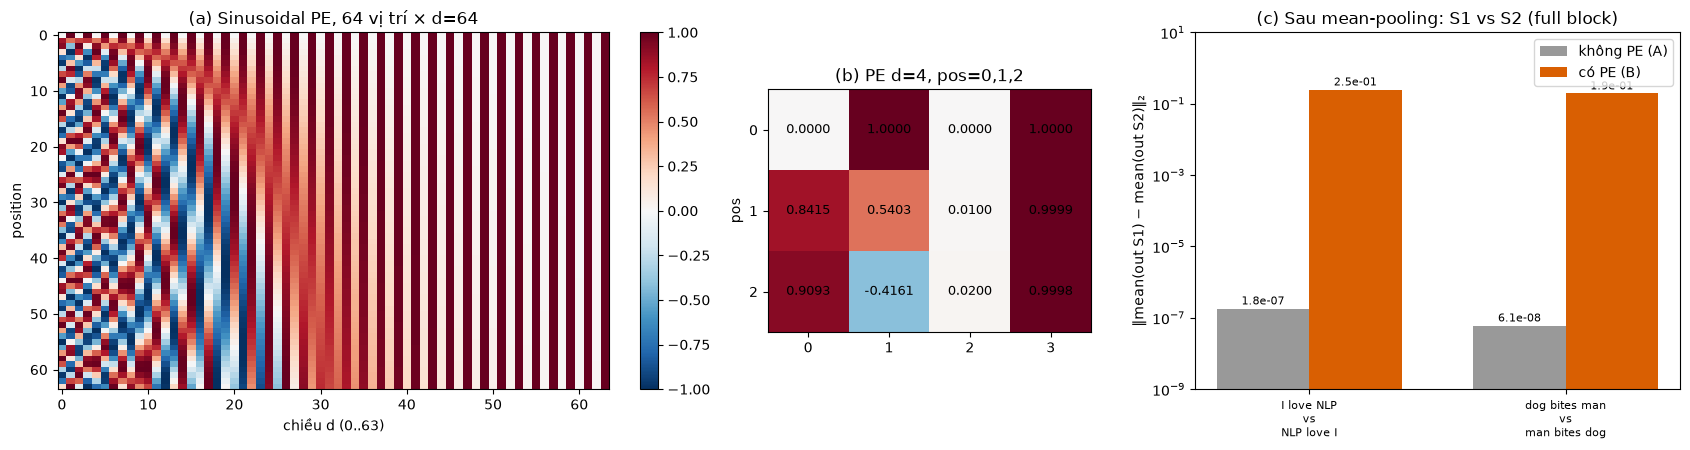

In [8]:
# positional_encoding.png: (a) heatmap PE, (b) PE d=4 pos 0..2, (c) khoang cach sau mean-pooling co/khong PE
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw=dict(width_ratios=[1.5, 0.8, 1.2]))
pe64 = sinusoidal_positional_encoding(64, 64).numpy()
im = ax[0].imshow(pe64, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1); ax[0].set_xlabel("chiều d (0..63)"); ax[0].set_ylabel("position")
ax[0].set_title("(a) Sinusoidal PE, 64 vị trí × d=64"); plt.colorbar(im, ax=ax[0], fraction=0.04)
pe4 = sinusoidal_positional_encoding(3, 4).numpy()
ax[1].imshow(pe4, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(3):
    for j in range(4): ax[1].text(j, i, f"{pe4[i, j]:.4f}", ha="center", va="center", fontsize=9)
ax[1].set_xticks(range(4)); ax[1].set_yticks(range(3)); ax[1].set_ylabel("pos"); ax[1].set_title("(b) PE d=4, pos=0,1,2")
sub = exp1_df[exp1_df.module == "full_block"]
labels_c = list(pairs); xs = np.arange(len(labels_c)); w = 0.36
for k, (use_pe, col, lab) in enumerate(((False, "#999999", "không PE (A)"), (True, "#d95f02", "có PE (B)"))):
    vals = [max(sub[(sub.pair == p) & (sub.PE == use_pe)].meanpool_diff_norm.iloc[0], 1e-9) for p in labels_c]
    bars = ax[2].bar(xs + (k - 0.5) * w, vals, w, color=col, label=lab)
    for b_, v_ in zip(bars, vals): ax[2].text(b_.get_x() + b_.get_width() / 2, v_ * 1.3, f"{v_:.1e}", ha="center", fontsize=8)
ax[2].set_yscale("log"); ax[2].set_ylim(1e-9, 10); ax[2].set_xticks(xs); ax[2].set_xticklabels([l.replace(" | ", "\nvs\n") for l in labels_c], fontsize=8)
ax[2].set_ylabel("‖mean(out S1) − mean(out S2)‖₂"); ax[2].set_title("(c) Sau mean-pooling: S1 vs S2 (full block)"); ax[2].legend()
plt.tight_layout(); plt.savefig(LAB07 / "positional_encoding.png", dpi=140); plt.show()

### Trả lời câu hỏi: Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự trở thành vấn đề?
Self-attention là hàm trên *tập* token: hoán vị hàng của X chỉ hoán vị hàng của đầu ra. Kết quả (bảng ở cell trên):
- **Không PE (A):** `S2_is_row_permutation_of_S1 = True` ở cả 2 cặp, cả attention-only lẫn full block (lệch ≤ 2.4e-7); cosine của cùng token ở hai câu = 1.0; sau mean-pooling hai câu lệch chỉ 6e-8…1.8e-7 (sai số float) → "dog bites man" và "man bites dog" **không phân biệt được**.
- **Có PE (B):** `False`; lệch khỏi hoán vị 0.146–1.300; pooled khác nhau 0.157 / 0.250 (I love NLP) và 0.223 / 0.194 (dog bites man).

Hạn chế: trọng số ngẫu nhiên → chỉ chứng minh *khả năng* phân biệt thứ tự. Trên IMDb (cell Exp 6 bên dưới) bỏ PE **không** làm kết quả tệ hơn; sự cần thiết của PE được chứng minh ở bài permutation, không ở task cảm xúc này.

## 5. Hạ tầng train / đánh giá (chung cho LSTM và Transformer)

In [9]:
_DS = {}
def loader(split, T, shuffle=False, seed=SEED):
    key = (split, T)
    if key not in _DS: _DS[key] = sm.ReviewDataset(enc[split], labels[split], T)      # keep_first truncation, PAD=0
    g = torch.Generator().manual_seed(seed)
    return DataLoader(_DS[key], batch_size=BATCH, shuffle=shuffle, generator=g, num_workers=0)

RUNS = {}
def fit(name, build, T, seed, epochs=EPOCHS, lr=LR, keep_model=None):
    # Train `epochs` epoch, chon checkpoint co val loss thap nhat, danh gia tren TEST.
    sm.set_seed(seed)
    model = build().to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    trl, vl, tel = loader("train", T, True, seed), loader("val", T), loader("test", T)
    hist = dict(train_loss=[], val_loss=[], val_acc=[]); best = (float("inf"), None, -1)
    if dev.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    for ep in range(epochs):
        hist["train_loss"].append(sm.train_one_epoch(model, trl, opt, dev))
        v = sm.evaluate(model, vl, dev)
        hist["val_loss"].append(float(v["loss"])); hist["val_acc"].append(float(v["accuracy"]))
        if v["loss"] < best[0]: best = (float(v["loss"]), {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}, ep)
    if dev.type == "cuda": torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0                       # gom ca validation moi epoch (giong LAB 05)
    peak = torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else float("nan")
    model.load_state_dict(best[1])
    test = sm.evaluate(model, tel, dev)
    run = dict(name=name, seed=seed, T=T, hist=hist, time=elapsed, params=sm.count_parameters(model), test=test,
               best_epoch=best[2] + 1, best_val_loss=best[0], peak_mb=peak)
    if keep_model if keep_model is not None else seed == SEED: run["model"] = model
    else: del model
    RUNS[(name, seed)] = run
    t = test
    print(f"{name:<18s} seed={seed} T={T:<3d} params={run['params']:,} time={elapsed:5.1f}s best_ep={run['best_epoch']} | "
          f"acc={t['accuracy']:.4f} P={t['precision']:.4f} R={t['recall']:.4f} F1={t['f1']:.4f}")
    return run

def tf_builder(heads=N_HEADS, pooling="mean", use_pe=True, T=MAX_LEN, layers=N_LAYERS):
    return lambda: TransformerClassifier(len(vocab), D_MODEL, heads, D_FF, layers, DROPOUT, pooling, use_pe, max_len=T)
lstm_builder = lambda: sm.SequenceClassifier(len(vocab), D_MODEL, D_MODEL, "lstm")

def multi(name, seeds=SEEDS):
    rs = [RUNS[(name, s)] for s in seeds if (name, s) in RUNS]
    a = np.array([r["test"]["accuracy"] for r in rs]); f = np.array([r["test"]["f1"] for r in rs]); t = np.array([r["time"] for r in rs])
    sd = lambda v: float(np.std(v, ddof=1)) if len(v) > 1 else float("nan")
    return dict(n_seeds=len(rs), acc_mean=float(a.mean()), acc_std=sd(a), f1_mean=float(f.mean()), f1_std=sd(f), time_mean=float(t.mean()),
                acc_by_seed=a.round(4).tolist(), f1_by_seed=f.round(4).tolist())
def log_run(experiment, config, name, **extra):
    r = RUNS[(name, SEED)]
    add_result(experiment, config, r["params"], r["time"], r["test"], run=name, best_epoch=r["best_epoch"],
               peak_cuda_mb=round(r["peak_mb"], 1), **{**{"multi_seed_" + k: v for k, v in multi(name).items()}, **extra})
print(f"Cau hinh chung: d_model={D_MODEL} d_ff={D_FF} layers={N_LAYERS} dropout={DROPOUT} | batch={BATCH} Adam lr={LR} epochs={EPOCHS} max_len={MAX_LEN} | seeds={SEEDS}")

Cau hinh chung: d_model=128 d_ff=256 layers=2 dropout=0.1 | batch=128 Adam lr=0.001 epochs=5 max_len=128 | seeds=(42, 43, 44)


## 6. Experiment 2 — số heads (d_model = 128 cố định)

In [10]:
for h in (1, 2, 4, 8):
    for s in SEEDS: fit(f"tf_h{h}_mean", tf_builder(heads=h), MAX_LEN, s)
rows = []
for h in (1, 2, 4, 8):
    r, m = RUNS[(f"tf_h{h}_mean", SEED)], multi(f"tf_h{h}_mean")
    rows.append(dict(heads=h, d_k=D_MODEL // h, params=r["params"], train_time_s=round(r["time"], 1), accuracy=round(r["test"]["accuracy"], 4), f1=round(r["test"]["f1"], 4),
                     acc_mean3=round(m["acc_mean"], 4), acc_std3=round(m["acc_std"], 4), f1_mean3=round(m["f1_mean"], 4), f1_std3=round(m["f1_std"], 4)))
    log_run("exp2_heads", f"heads={h}, d_k={D_MODEL // h}, d_model={D_MODEL}, pool=mean, T={MAX_LEN}", f"tf_h{h}_mean", heads=h, d_k=D_MODEL // h)
exp2_df = pd.DataFrame(rows); print(exp2_df.to_string(index=False))

tf_h1_mean         seed=42 T=128 params=4,105,089 time= 42.8s best_ep=3 | acc=0.8337 P=0.8177 R=0.8588 F1=0.8378


tf_h1_mean         seed=43 T=128 params=4,105,089 time= 47.6s best_ep=5 | acc=0.8408 P=0.8364 R=0.8474 F1=0.8418


tf_h1_mean         seed=44 T=128 params=4,105,089 time= 45.7s best_ep=3 | acc=0.8324 P=0.8411 R=0.8196 F1=0.8302


tf_h2_mean         seed=42 T=128 params=4,105,089 time= 52.7s best_ep=4 | acc=0.8349 P=0.8589 R=0.8014 F1=0.8292


tf_h2_mean         seed=43 T=128 params=4,105,089 time= 53.4s best_ep=4 | acc=0.8374 P=0.8737 R=0.7888 F1=0.8291


tf_h2_mean         seed=44 T=128 params=4,105,089 time= 53.8s best_ep=3 | acc=0.8240 P=0.8616 R=0.7720 F1=0.8143


... (2 outputs left out)

tf_h4_mean         seed=44 T=128 params=4,105,089 time= 64.8s best_ep=3 | acc=0.8296 P=0.8499 R=0.8006 F1=0.8245


tf_h8_mean         seed=42 T=128 params=4,105,089 time= 85.7s best_ep=3 | acc=0.8353 P=0.8309 R=0.8420 F1=0.8364


tf_h8_mean         seed=43 T=128 params=4,105,089 time= 81.9s best_ep=3 | acc=0.8302 P=0.8138 R=0.8564 F1=0.8345


tf_h8_mean         seed=44 T=128 params=4,105,089 time= 86.2s best_ep=3 | acc=0.8337 P=0.8512 R=0.8088 F1=0.8295
 heads  d_k  params  train_time_s  accuracy     f1  acc_mean3  acc_std3  f1_mean3  f1_std3
     1  128 4105089          42.8    0.8337 0.8378     0.8356    0.0045    0.8366   0.0059
     2   64 4105089          52.7    0.8349 0.8292     0.8321    0.0071    0.8242   0.0085
     4   32 4105089          63.7    0.8382 0.8349     0.8353    0.0050    0.8339   0.0089
     8   16 4105089          85.7    0.8353 0.8364     0.8331    0.0026    0.8335   0.0036


### Kết quả Experiment 2 (số heads, d_model = 128 cố định)
| heads | d_k | params | thời gian (s) | acc | F1 | acc 3 seeds | F1 3 seeds |
|---|---|---|---|---|---|---|---|
| 1 | 128 | 4,105,089 | 42.8 | 0.8337 | 0.8378 | 0.8356 ± 0.0045 | 0.8366 ± 0.0059 |
| 2 | 64 | 4,105,089 | 52.7 | 0.8349 | 0.8292 | 0.8321 ± 0.0071 | 0.8242 ± 0.0085 |
| 4 | 32 | 4,105,089 | 63.7 | 0.8382 | 0.8349 | 0.8353 ± 0.0050 | 0.8339 ± 0.0089 |
| 8 | 16 | 4,105,089 | 85.7 | 0.8353 | 0.8364 | 0.8331 ± 0.0026 | 0.8335 ± 0.0036 |

### Trả lời câu hỏi: Tăng số heads có đồng nghĩa với tăng representation dimension không?
**Không.** Q/K/V/W^O đều d_model×d_model nên #params giữ nguyên 4,105,089; concat luôn là h·d_k = 128. Heads chỉ *chia* 128 chiều thành h subspace. Accuracy/F1 không tăng đơn điệu, chênh lệch nằm trong độ lệch chuẩn giữa seed → tăng heads **không** chắc chắn tăng accuracy; thời gian tăng (mean 3 seeds 45.4 → 53.3 → 64.5 → 84.6 s).

### Trả lời câu hỏi: Khi d_model cố định, tăng số heads làm d_k thay đổi như thế nào?
d_k = d_model/h → 128, 64, 32, 16: **giảm tỉ lệ nghịch** khi h tăng.

## 7. Experiment 6 — pooling (mean vs CLS-style) và ablation bỏ PE trên IMDb

In [11]:
for s in SEEDS:
    fit("tf_h4_cls", tf_builder(pooling="cls"), MAX_LEN, s)
    fit("tf_h4_nope", tf_builder(use_pe=False), MAX_LEN, s)
rows = []
for name, label in (("tf_h4_mean", "Mean (mask padding)"), ("tf_h4_cls", "CLS-style (learned [CLS] ở đầu)")):
    r, m = RUNS[(name, SEED)], multi(name)
    rows.append(dict(pooling=label, params=r["params"], accuracy=round(r["test"]["accuracy"], 4), f1=round(r["test"]["f1"], 4), train_time_s=round(r["time"], 1),
                     acc_mean3=round(m["acc_mean"], 4), acc_std3=round(m["acc_std"], 4), f1_mean3=round(m["f1_mean"], 4), f1_std3=round(m["f1_std"], 4)))
exp6_df = pd.DataFrame(rows); print(exp6_df.to_string(index=False))
log_run("exp6_pooling", "pooling=mean (heads=4, T=128)", "tf_h4_mean")
log_run("exp6_pooling", "pooling=cls (heads=4, T=128)", "tf_h4_cls")
log_run("exp1b_pe_ablation", "mean pooling, PE=True (heads=4)", "tf_h4_mean", use_pe=True)
log_run("exp1b_pe_ablation", "mean pooling, PE=False (heads=4)", "tf_h4_nope", use_pe=False)
print("\nAblation PE (test):")
print(pd.DataFrame([dict(PE=pe_, **{k: round(v, 4) for k, v in multi(n).items() if isinstance(v, float)}) for pe_, n in ((True, "tf_h4_mean"), (False, "tf_h4_nope"))]).to_string(index=False))

tf_h4_cls          seed=42 T=128 params=4,105,217 time= 72.5s best_ep=3 | acc=0.8307 P=0.8089 R=0.8660 F1=0.8365


tf_h4_nope         seed=42 T=128 params=4,105,089 time= 68.0s best_ep=3 | acc=0.8332 P=0.8038 R=0.8816 F1=0.8409


tf_h4_cls          seed=43 T=128 params=4,105,217 time= 71.9s best_ep=4 | acc=0.8333 P=0.8447 R=0.8168 F1=0.8305


tf_h4_nope         seed=43 T=128 params=4,105,089 time= 68.4s best_ep=4 | acc=0.8404 P=0.8386 R=0.8430 F1=0.8408


tf_h4_cls          seed=44 T=128 params=4,105,217 time= 74.9s best_ep=3 | acc=0.8352 P=0.8272 R=0.8474 F1=0.8372


tf_h4_nope         seed=44 T=128 params=4,105,089 time= 68.3s best_ep=3 | acc=0.8437 P=0.8511 R=0.8332 F1=0.8420
                        pooling  params  accuracy     f1  train_time_s  acc_mean3  acc_std3  f1_mean3  f1_std3
            Mean (mask padding) 4105089    0.8382 0.8349          63.7     0.8353    0.0050    0.8339   0.0089
CLS-style (learned [CLS] ở đầu) 4105217    0.8307 0.8365          72.5     0.8331    0.0023    0.8347   0.0037

Ablation PE (test):
   PE  acc_mean  acc_std  f1_mean  f1_std  time_mean
 True    0.8353   0.0050   0.8339  0.0089    64.4871
False    0.8391   0.0054   0.8413  0.0007    68.2415


### Kết quả Experiment 6 (pooling)
| pooling | acc (seed 42) | F1 (seed 42) | thời gian (s) | acc 3 seeds | F1 3 seeds |
|---|---|---|---|---|---|
| Mean (mask padding) | 0.8382 | 0.8349 | 63.7 | 0.8353 ± 0.0050 | 0.8339 ± 0.0089 |
| CLS-style | 0.8307 | 0.8365 | 72.5 | 0.8331 ± 0.0023 | 0.8347 ± 0.0037 |

### Trả lời câu hỏi: Cách lấy sequence representation có ảnh hưởng tới classification không?
Chênh lệch ≤ 0.25 điểm, nhỏ hơn độ lệch chuẩn → **không thấy ảnh hưởng đo được** ở thiết lập này (3 seeds, 5 epoch, train từ đầu). CLS chậm hơn (T+1 token), chỉ thêm 128 tham số.

### Kết quả bổ sung: bỏ positional encoding có làm giảm kết quả trên IMDb không?
Không PE acc 0.8391 ± 0.0054 / F1 0.8413 ± 0.0007, có PE 0.8353 ± 0.0050 / 0.8339 ± 0.0089 → bỏ PE không giảm trên IMDb (cảm xúc chủ yếu do từ vựng quyết định).

## 8. Experiment 4 — LSTM vs Transformer (cùng dataset/split/vocab/embedding dim=128/batch/Adam/lr/epochs)

In [12]:
for s in SEEDS: fit("lstm", lstm_builder, MAX_LEN, s)
rows = []
for name, label in (("lstm", "LSTM (emb128, hidden128)"), ("tf_h4_mean", "Transformer (2 layers, 4 heads, d_ff 256, mean)")):
    r, m = RUNS[(name, SEED)], multi(name); t = r["test"]
    rows.append(dict(model=label, params=r["params"], non_embedding_params=r["params"] - len(vocab) * D_MODEL, train_time_s=round(r["time"], 1),
                     accuracy=round(t["accuracy"], 4), precision=round(t["precision"], 4), recall=round(t["recall"], 4), f1=round(t["f1"], 4),
                     f1_mean3=round(m["f1_mean"], 4), f1_std3=round(m["f1_std"], 4), time_mean3=round(m["time_mean"], 1)))
exp4_df = pd.DataFrame(rows); print(exp4_df.to_string(index=False))
log_run("exp4_lstm_vs_transformer", "LSTM emb=128 hid=128 T=128", "lstm", non_embedding_params=RUNS[("lstm", SEED)]["params"] - len(vocab) * D_MODEL)
log_run("exp4_lstm_vs_transformer", "Transformer 2L h=4 d_ff=256 mean T=128 (cung run voi exp2 heads=4)", "tf_h4_mean",
        non_embedding_params=RUNS[("tf_h4_mean", SEED)]["params"] - len(vocab) * D_MODEL)

lstm               seed=42 T=128 params=3,972,225 time= 60.9s best_ep=5 | acc=0.8228 P=0.8339 R=0.8062 F1=0.8198


lstm               seed=43 T=128 params=3,972,225 time= 56.4s best_ep=5 | acc=0.8126 P=0.7751 R=0.8808 F1=0.8246


lstm               seed=44 T=128 params=3,972,225 time= 55.0s best_ep=5 | acc=0.8210 P=0.8233 R=0.8174 F1=0.8204
                                          model  params  non_embedding_params  train_time_s  accuracy  precision  recall     f1  f1_mean3  f1_std3  time_mean3
                       LSTM (emb128, hidden128) 3972225                132225          60.9    0.8228     0.8339  0.8062 0.8198    0.8216   0.0026        57.4
Transformer (2 layers, 4 heads, d_ff 256, mean) 4105089                265089          63.7    0.8382     0.8523  0.8182 0.8349    0.8339   0.0089        64.5


### Trả lời câu hỏi: Sự khác biệt về performance giữa LSTM và Transformer có thể xuất phát từ những thành phần architecture nào?
| model | params (không-embedding) | thời gian (s) | acc | precision | recall | F1 | acc 3 seeds | F1 3 seeds |
|---|---|---|---|---|---|---|---|---|
| LSTM | 3,972,225 (132,225) | 60.9 | 0.8228 | 0.8339 | 0.8062 | 0.8198 | 0.8188 ± 0.0054 | 0.8216 ± 0.0026 |
| Transformer | 4,105,089 (265,089) | 63.7 | 0.8382 | 0.8523 | 0.8182 | 0.8349 | 0.8353 ± 0.0050 | 0.8339 ± 0.0089 |

Transformer hơn ~1.2–1.7 điểm (≈ 2–3 std, chỉ 3 seed → xu hướng, không phải kết luận chắc); cả hai thấp hơn TF-IDF+LR của LAB 05 (acc 0.8958) vì chỉ giữ 51% token và train từ đầu.
**Thành phần kiến trúc có thể gây khác biệt** (giả thuyết, *chưa tách bằng ablation*): (i) tương tác token–token trực tiếp (đường đi 1 bước thay vì tối đa 128 bước); (ii) pooling — mean trên mọi vị trí so với trạng thái cuối của LSTM (hai mô hình khác pooling nên không quy riêng cho attention); (iii) residual + LayerNorm giúp tối ưu — val loss LSTM còn giảm ở epoch 5 (best epoch = 5 cả 3 seed), Transformer tốt nhất ở epoch 3–5 rồi overfit; (iv) tham số không-embedding gấp đôi.

## 9. Experiment 5 — max_length ∈ {32, 64, 128, 256}

In [13]:
for T in (32, 64, 256): fit(f"tf_h4_mean_T{T}", tf_builder(T=T), T, SEED)
RUNS[("tf_h4_mean_T128", SEED)] = RUNS[("tf_h4_mean", SEED)]
for T in (32, 64, 128, 256): fit(f"lstm_T{T}", lstm_builder, T, SEED) if T != 128 else RUNS.__setitem__(("lstm_T128", SEED), RUNS[("lstm", SEED)])

total_tokens = int(tok_len.sum()); BH = BATCH * N_HEADS
rows = []
for T in (32, 64, 128, 256):
    r, rl = RUNS[(f"tf_h4_mean_T{T}", SEED)], RUNS[(f"lstm_T{T}", SEED)]
    retained = float(np.minimum(tok_len, T).sum() / total_tokens)
    trunc = float((tok_len > T).mean())
    mem_theory_mb_layer = BH * T * T * 4 / 2**20
    rows.append(dict(max_length=T, tokens_retained_pct=round(100 * retained, 2), docs_truncated_pct=round(100 * trunc, 2), T2_per_head=T * T,
                     attn_matrix_MB_per_layer_theory=round(mem_theory_mb_layer, 1), peak_cuda_MB_train_measured=round(r["peak_mb"], 0),
                     tf_train_time_s=round(r["time"], 1), tf_f1=round(r["test"]["f1"], 4), tf_acc=round(r["test"]["accuracy"], 4),
                     lstm_train_time_s=round(rl["time"], 1), lstm_f1=round(rl["test"]["f1"], 4)))
    add_result("exp5_seq_length", f"transformer T={T}", r["params"], r["time"], r["test"], max_length=T, tokens_retained_pct=round(100 * retained, 2),
               docs_truncated_pct=round(100 * trunc, 2), T2=T * T, attn_matrix_MB_per_layer_theory=round(mem_theory_mb_layer, 2),
               attn_formula=f"B*h*T^2*4 bytes with B={BATCH}, h={N_HEADS}", peak_cuda_mb_measured=round(r["peak_mb"], 1), best_epoch=r["best_epoch"])
    add_result("exp5_seq_length", f"lstm T={T}", rl["params"], rl["time"], rl["test"], max_length=T, peak_cuda_mb_measured=round(rl["peak_mb"], 1))
exp5_df = pd.DataFrame(rows); print(exp5_df.to_string(index=False))
print("128 -> 256: T^2 =", 128 * 128, "->", 256 * 256, "(x%.0f)" % (256 * 256 / (128 * 128)))

tf_h4_mean_T32     seed=42 T=32  params=4,105,089 time= 37.2s best_ep=5 | acc=0.7453 P=0.7488 R=0.7382 F1=0.7435


tf_h4_mean_T64     seed=42 T=64  params=4,105,089 time= 40.6s best_ep=5 | acc=0.7954 P=0.7847 R=0.8142 F1=0.7992


tf_h4_mean_T256    seed=42 T=256 params=4,105,089 time=161.5s best_ep=4 | acc=0.8675 P=0.8713 R=0.8624 F1=0.8668


lstm_T32           seed=42 T=32  params=3,972,225 time= 31.5s best_ep=3 | acc=0.7421 P=0.7330 R=0.7616 F1=0.7470


lstm_T64           seed=42 T=64  params=3,972,225 time= 37.7s best_ep=4 | acc=0.7853 P=0.7908 R=0.7758 F1=0.7832


lstm_T256          seed=42 T=256 params=3,972,225 time= 93.5s best_ep=5 | acc=0.8576 P=0.8521 R=0.8654 F1=0.8587
 max_length  tokens_retained_pct  docs_truncated_pct  T2_per_head  attn_matrix_MB_per_layer_theory  peak_cuda_MB_train_measured  tf_train_time_s  tf_f1  tf_acc  lstm_train_time_s  lstm_f1
         32                13.65               99.72         1024                              2.0                        353.0             37.2 0.7435  0.7453               31.5   0.7470
         64                27.02               94.92         4096                              8.0                        474.0             40.6 0.7992  0.7954               37.7   0.7832
        128                51.07               74.96        16384                             32.0                        518.0             63.7 0.8349  0.8382               60.9   0.8198
        256                76.79               29.27        65536                            128.0                       1438.0        

In [14]:
# Micro-benchmark: 1 buoc fwd+bwd (B=16) theo T, Transformer vs LSTM  (bang chung cho T^2 vs ~tuyen tinh; khong phai train that)
def bench(build, T, B=16, iters=20):
    try:
        m = build(T).to(dev).train(); ids = torch.randint(2, len(vocab), (B, T), device=dev); lens = torch.full((B,), T)
        for _ in range(3): m(ids, lens).sum().backward()
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.perf_counter()
        for _ in range(iters): m.zero_grad(set_to_none=True); m(ids, lens).sum().backward()
        torch.cuda.synchronize(); ms = (time.perf_counter() - t0) / iters * 1000
        mem = torch.cuda.max_memory_allocated() / 2**20; del m; torch.cuda.empty_cache(); return ms, mem
    except torch.OutOfMemoryError:
        torch.cuda.empty_cache(); return float("nan"), float("nan")
rows = []
for T in (64, 128, 256, 512, 1024):
    ms_t, mem_t = bench(lambda T=T: tf_builder(T=T)(), T); ms_l, mem_l = bench(lambda T=T: lstm_builder(), T)
    rows.append(dict(T=T, transformer_ms_per_step=round(ms_t, 1), lstm_ms_per_step=round(ms_l, 1), ratio_tf_over_lstm=round(ms_t / ms_l, 2),
                     transformer_peak_MB=round(mem_t, 0), lstm_peak_MB=round(mem_l, 0)))
    add_result("exp5b_benchmark", f"fwd+bwd B=16 T={T}", None, None, None, transformer_ms=ms_t, lstm_ms=ms_l, transformer_peak_mb=mem_t, lstm_peak_mb=mem_l)
bench_df = pd.DataFrame(rows); print(bench_df.to_string(index=False))

   T  transformer_ms_per_step  lstm_ms_per_step  ratio_tf_over_lstm  transformer_peak_MB  lstm_peak_MB
  64                     13.8              15.3                0.91                456.0         451.0
 128                     16.7              25.0                0.67                486.0         457.0
 256                     17.1              39.4                0.43                574.0         472.0
 512                     46.3              78.8                0.59                910.0         488.0
1024                    152.9             135.1                1.13               2184.0         532.0


### Kết quả Experiment 5 (max_length)
| T | tokens giữ lại | docs bị cắt | T² | attention/layer lý thuyết | peak CUDA (đo) | thời gian Tf (s) | F1 Tf | F1 LSTM |
|---|---|---|---|---|---|---|---|---|
| 32 | 13.65% | 99.72% | 1,024 | 2 MB | 353 MB | 37.2 | 0.7435 | 0.7470 |
| 64 | 27.02% | 94.92% | 4,096 | 8 MB | 474 MB | 40.6 | 0.7992 | 0.7832 |
| 128 | 51.07% | 74.96% | 16,384 | 32 MB | 518 MB | 63.7 | 0.8349 | 0.8198 |
| 256 | 76.79% | 29.27% | 65,536 | 128 MB | 1,438 MB | 161.5 | 0.8668 | 0.8587 |

(lý thuyết = B·h·T²·4 byte cho *một* ma trận scores của *một* layer; peak đo gồm cả tham số, optimizer, activations.) **128 → 256:** số phần tử attention 16,384 → 65,536 (×4); thời gian ×2.5; peak ×2.8; F1 chỉ +0.032. Micro-benchmark: T=512 → 1024 thời gian 46.3 → 152.9 ms (×3.3), peak 910 → 2,184 MB; ở T=1024 Transformer **chậm hơn** LSTM (152.9 vs 135.1 ms) và dùng bộ nhớ gấp ~4 (2,184 vs 532 MB).

### Trả lời câu hỏi: Tại sao Transformer không đơn giản giải quyết mọi vấn đề bằng cách tăng sequence length?
Chi phí thời gian/bộ nhớ O(T²) (số liệu trên); lợi ích F1 giảm dần so với chi phí; ngay T=256 vẫn có 29% review bị cắt; độ dài tối đa phải cố định lúc huấn luyện.

## 10. Learning curves

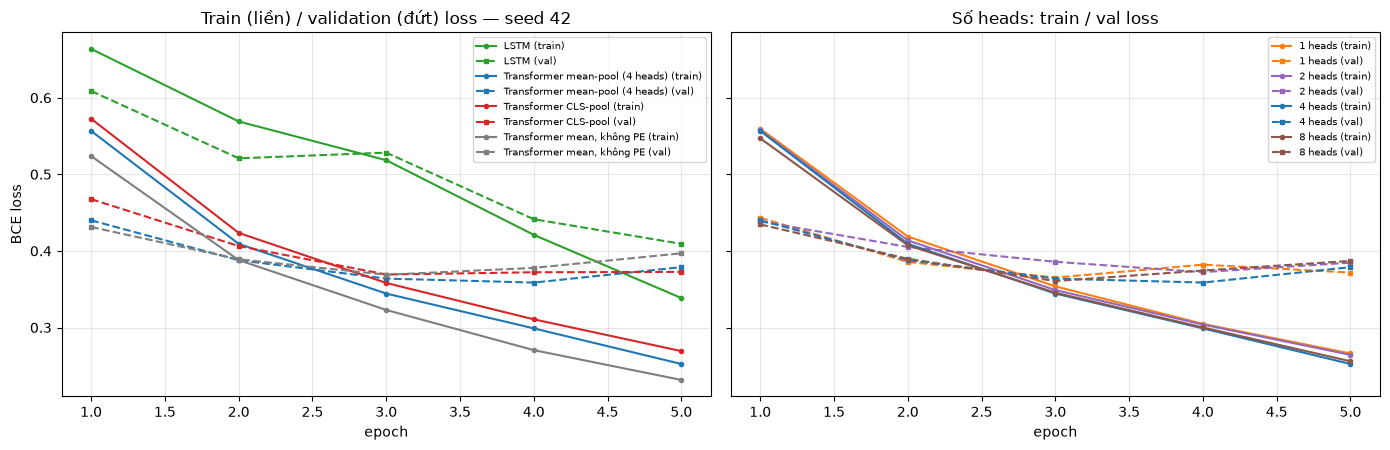

       run                          train_loss                            val_loss  best_epoch  final_gap_val_minus_train  val_up_after_best
      lstm [0.664, 0.569, 0.518, 0.421, 0.338] [0.609, 0.521, 0.528, 0.441, 0.409]           5                      0.071              False
tf_h1_mean [0.559, 0.419, 0.354, 0.305, 0.266] [0.443, 0.386, 0.365, 0.382, 0.372]           3                      0.106               True
tf_h2_mean [0.557, 0.414, 0.349, 0.304, 0.264] [0.439, 0.405, 0.386, 0.372, 0.385]           4                      0.120               True
tf_h4_mean [0.557, 0.409, 0.344, 0.299, 0.252]  [0.44, 0.388, 0.364, 0.359, 0.379]           4                      0.126               True
tf_h8_mean   [0.547, 0.407, 0.345, 0.3, 0.256]  [0.435, 0.39, 0.361, 0.374, 0.387]           3                      0.131               True
 tf_h4_cls [0.573, 0.424, 0.358, 0.311, 0.269] [0.468, 0.406, 0.369, 0.372, 0.373]           3                      0.103               True
tf_h4_nope  [

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
main = [("lstm", "LSTM", "tab:green"), ("tf_h4_mean", "Transformer mean-pool (4 heads)", "tab:blue"),
        ("tf_h4_cls", "Transformer CLS-pool", "tab:red"), ("tf_h4_nope", "Transformer mean, không PE", "tab:gray")]
for name, lab, c in main:
    h_ = RUNS[(name, SEED)]["hist"]; ep = np.arange(1, EPOCHS + 1)
    ax[0].plot(ep, h_["train_loss"], "-o", color=c, label=lab + " (train)", ms=3); ax[0].plot(ep, h_["val_loss"], "--s", color=c, label=lab + " (val)", ms=3)
ax[0].set_title("Train (liền) / validation (đứt) loss — seed 42"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE loss"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
for h, c in zip((1, 2, 4, 8), ("tab:orange", "tab:purple", "tab:blue", "tab:brown")):
    h_ = RUNS[(f"tf_h{h}_mean", SEED)]["hist"]
    ax[1].plot(ep, h_["train_loss"], "-o", color=c, label=f"{h} heads (train)", ms=3); ax[1].plot(ep, h_["val_loss"], "--s", color=c, label=f"{h} heads (val)", ms=3)
ax[1].set_title("Số heads: train / val loss"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(LAB07 / "learning_curves.png", dpi=140); plt.show()
rows = []
for name in ("lstm", "tf_h1_mean", "tf_h2_mean", "tf_h4_mean", "tf_h8_mean", "tf_h4_cls", "tf_h4_nope"):
    h_ = RUNS[(name, SEED)]["hist"]
    rows.append(dict(run=name, train_loss=[round(v, 3) for v in h_["train_loss"]], val_loss=[round(v, 3) for v in h_["val_loss"]], best_epoch=RUNS[(name, SEED)]["best_epoch"],
                     final_gap_val_minus_train=round(h_["val_loss"][-1] - h_["train_loss"][-1], 3), val_up_after_best=h_["val_loss"][-1] > min(h_["val_loss"]) + 1e-9))
curve_df = pd.DataFrame(rows); print(curve_df.to_string(index=False))

### Trả lời câu hỏi: Learning curves cho thấy overfitting, underfitting, hội tụ hay mất ổn định?
- **Transformer (mọi cấu hình): overfitting.** Train loss giảm đều (4 heads: 0.557 → 0.252) trong khi val loss chạm đáy rồi tăng lại (4 heads: min 0.359 ở epoch 4 → 0.379 ở epoch 5; 1 head min 0.365 ở epoch 3; 8 heads min 0.361 ở epoch 3); khoảng cách val − train cuối 0.10–0.13. Bỏ PE có khoảng cách lớn nhất (0.165; val 0.369 → 0.397); CLS-pool val gần phẳng (0.369 → 0.372 → 0.373).
- **LSTM: chưa hội tụ / underfit ở 5 epoch.** Train 0.664 → 0.338, val 0.609 → 0.409, best epoch = 5 và val còn giảm; không có dấu hiệu overfit.
- **Convergence:** Transformer hội tụ nhanh hơn (val loss epoch 1: 0.44 so với 0.609 của LSTM).
- **Instability:** nhẹ — val loss LSTM có nhịp tăng ở epoch 3 (0.521 → 0.528), 2 heads không đơn điệu (0.439, 0.405, 0.386, 0.372, 0.385); không có phân kỳ. Vì vậy chọn checkpoint theo val loss thấp nhất.

## 11. Confusion matrix (test, seed 42)

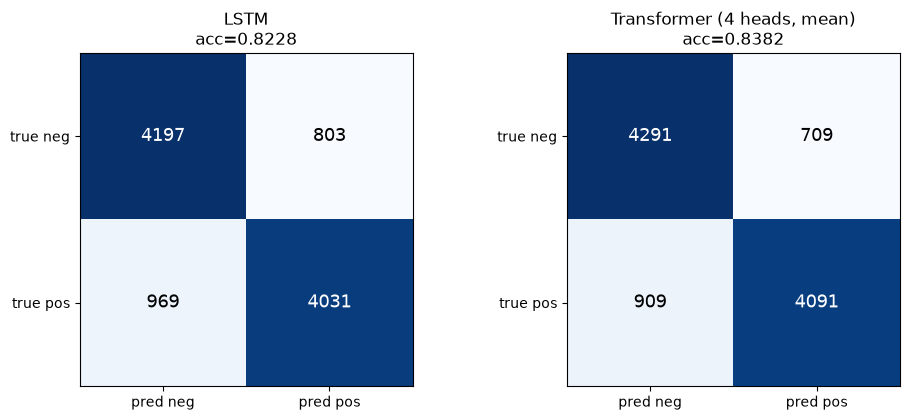

{'lstm': [[4197, 803], [969, 4031]], 'tf_h4_mean': [[4291, 709], [909, 4091]]}  layout [[TN,FP],[FN,TP]]


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.3))
for a, (name, title) in zip(ax, (("lstm", "LSTM"), ("tf_h4_mean", "Transformer (4 heads, mean)"))):
    cm = RUNS[(name, SEED)]["test"]["confusion_matrix"]; im = a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["pred neg", "pred pos"]); a.set_yticklabels(["true neg", "true pos"])
    a.set_title(f"{title}\nacc={RUNS[(name, SEED)]['test']['accuracy']:.4f}")
plt.tight_layout(); plt.savefig(LAB07 / "confusion_matrix.png", dpi=140); plt.show()
print({n: RUNS[(n, SEED)]["test"]["confusion_matrix"].tolist() for n in ("lstm", "tf_h4_mean")}, " layout [[TN,FP],[FN,TP]]")

**Nhận xét confusion matrix (test, 0 = neg, 1 = pos):** Transformer [[TN 4291, FP 709],[FN 909, TP 4091]] (acc 0.8382); LSTM [[4197, 803],[969, 4031]] (acc 0.8228). Cả hai sai nhiều FN hơn FP (909 vs 709; 969 vs 803); tức cả hai mô hình có xu hướng đoán thiếu nhãn positive (chưa tách nguyên nhân).

## 12. Experiment 3 — head diversity (mô hình 4 heads, mean pooling, seed 42)

Định lượng trên 500 review test ngẫu nhiên (≥10 token, seed 42, cắt 128 token), chỉ token thật (không PAD). Không gán nhãn syntax/semantics cho head.

In [17]:
model = RUNS[("tf_h4_mean", SEED)]["model"].eval()
rng = np.random.RandomState(SEED)
sample_idx = rng.choice([i for i, s in enumerate(enc["test"]) if len(s) >= 10], 500, replace=False)

@torch.no_grad()
def get_attn(m, ids):
    x = torch.tensor([ids[:MAX_LEN]], device=dev)
    _, attns = m(x, return_attn=True)
    return [a[0].cpu().numpy() for a in attns]                       # moi layer: (heads, n, n)

L, H = len(model.blocks), model.blocks[0].attn.n_heads
acc = {k: np.zeros((L, H)) for k in ("entropy_norm", "self_mass", "local_pm1_mass", "mean_rel_distance", "first_token_mass", "cos_to_uniform")}
cosm = np.zeros((L, H, H))
for i in sample_idx:
    for l, A in enumerate(get_attn(model, enc["test"][i])):
        n = A.shape[-1]; idx = np.arange(n)
        acc["entropy_norm"][l] += (-(A * np.log(A + 1e-12)).sum(-1).mean(-1)) / np.log(n)
        acc["self_mass"][l] += A[:, idx, idx].mean(-1)
        band = (np.abs(idx[:, None] - idx[None]) <= 1)
        acc["local_pm1_mass"][l] += (A * band).sum(-1).mean(-1)
        acc["mean_rel_distance"][l] += (A * (np.abs(idx[:, None] - idx[None]) / n)).sum(-1).mean(-1)
        acc["first_token_mass"][l] += A[:, :, 0].mean(-1)
        flat = A.reshape(H, -1); flat = flat / np.linalg.norm(flat, axis=1, keepdims=True)
        u = np.full(n * n, 1.0 / n); u /= np.linalg.norm(u)
        acc["cos_to_uniform"][l] += flat @ u; cosm[l] += flat @ flat.T
N = len(sample_idx); acc = {k: v / N for k, v in acc.items()}; cosm /= N
head_stats = []
for l in range(L):
    df_ = pd.DataFrame({k: v[l] for k, v in acc.items()}, index=[f"head{h + 1}" for h in range(H)]); print(f"--- layer {l + 1} ---"); print(df_.round(3).to_string())
    print("cosine giữa attention map của các head (trung bình trên 500 doc):"); print(pd.DataFrame(cosm[l], index=df_.index, columns=df_.index).round(3).to_string())
    off = cosm[l][~np.eye(H, dtype=bool)]; print(f"cos off-diagonal: mean={off.mean():.3f} min={off.min():.3f} max={off.max():.3f}\n")
    for h in range(H):
        head_stats.append(dict(layer=l + 1, head=h + 1, **{k: float(v[l, h]) for k, v in acc.items()}, max_cos_with_other_head=float(np.max(np.delete(cosm[l][h], h)))))
        add_result("exp3_head_diversity", f"layer={l + 1} head={h + 1}", **head_stats[-1])

# Ablation: zero dau ra cua 1 head (truoc W^O) -> do giam accuracy tren VALIDATION
def eval_ablate(l, hd):
    dk = model.blocks[l].attn.d_k
    def pre(mod, args):
        x = args[0].clone(); x[..., hd * dk:(hd + 1) * dk] = 0; return (x,)
    hdl = model.blocks[l].attn.w_o.register_forward_pre_hook(pre)
    try: return sm.evaluate(model, loader("val", MAX_LEN), dev)
    finally: hdl.remove()
base = sm.evaluate(model, loader("val", MAX_LEN), dev); print(f"val acc (không ablate) = {base['accuracy']:.4f}")
abl = []
for l in range(L):
    for hd in range(H):
        r = eval_ablate(l, hd); abl.append(dict(layer=l + 1, head=hd + 1, val_acc=round(r["accuracy"], 4), drop=round(base["accuracy"] - r["accuracy"], 4)))
        add_result("exp3_head_ablation", f"layer={l + 1} head={hd + 1} zeroed", None, None, None, val_acc=r["accuracy"], val_acc_drop=base["accuracy"] - r["accuracy"])
print(pd.DataFrame(abl).to_string(index=False))

--- layer 1 ---
       entropy_norm  self_mass  local_pm1_mass  mean_rel_distance  first_token_mass  cos_to_uniform
head1         0.841      0.008           0.026              0.338             0.009           0.451
head2         0.826      0.008           0.024              0.361             0.015           0.419
head3         0.830      0.011           0.029              0.324             0.010           0.431
head4         0.769      0.009           0.025              0.351             0.012           0.360
cosine giữa attention map của các head (trung bình trên 500 doc):
       head1  head2  head3  head4
head1  1.000  0.253  0.251  0.223
head2  0.253  1.000  0.227  0.203
head3  0.251  0.227  1.000  0.215
head4  0.223  0.203  0.215  1.000
cos off-diagonal: mean=0.229 min=0.203 max=0.253

--- layer 2 ---
       entropy_norm  self_mass  local_pm1_mass  mean_rel_distance  first_token_mass  cos_to_uniform
head1         0.683      0.009           0.026              0.346             0.00

val acc (không ablate) = 0.8446


 layer  head  val_acc    drop
     1     1   0.8370  0.0076
     1     2   0.8370  0.0076
     1     3   0.8376  0.0071
     1     4   0.8406  0.0040
     2     1   0.8455 -0.0009
     2     2   0.8435  0.0011
     2     3   0.8419  0.0028
     2     4   0.8436  0.0010


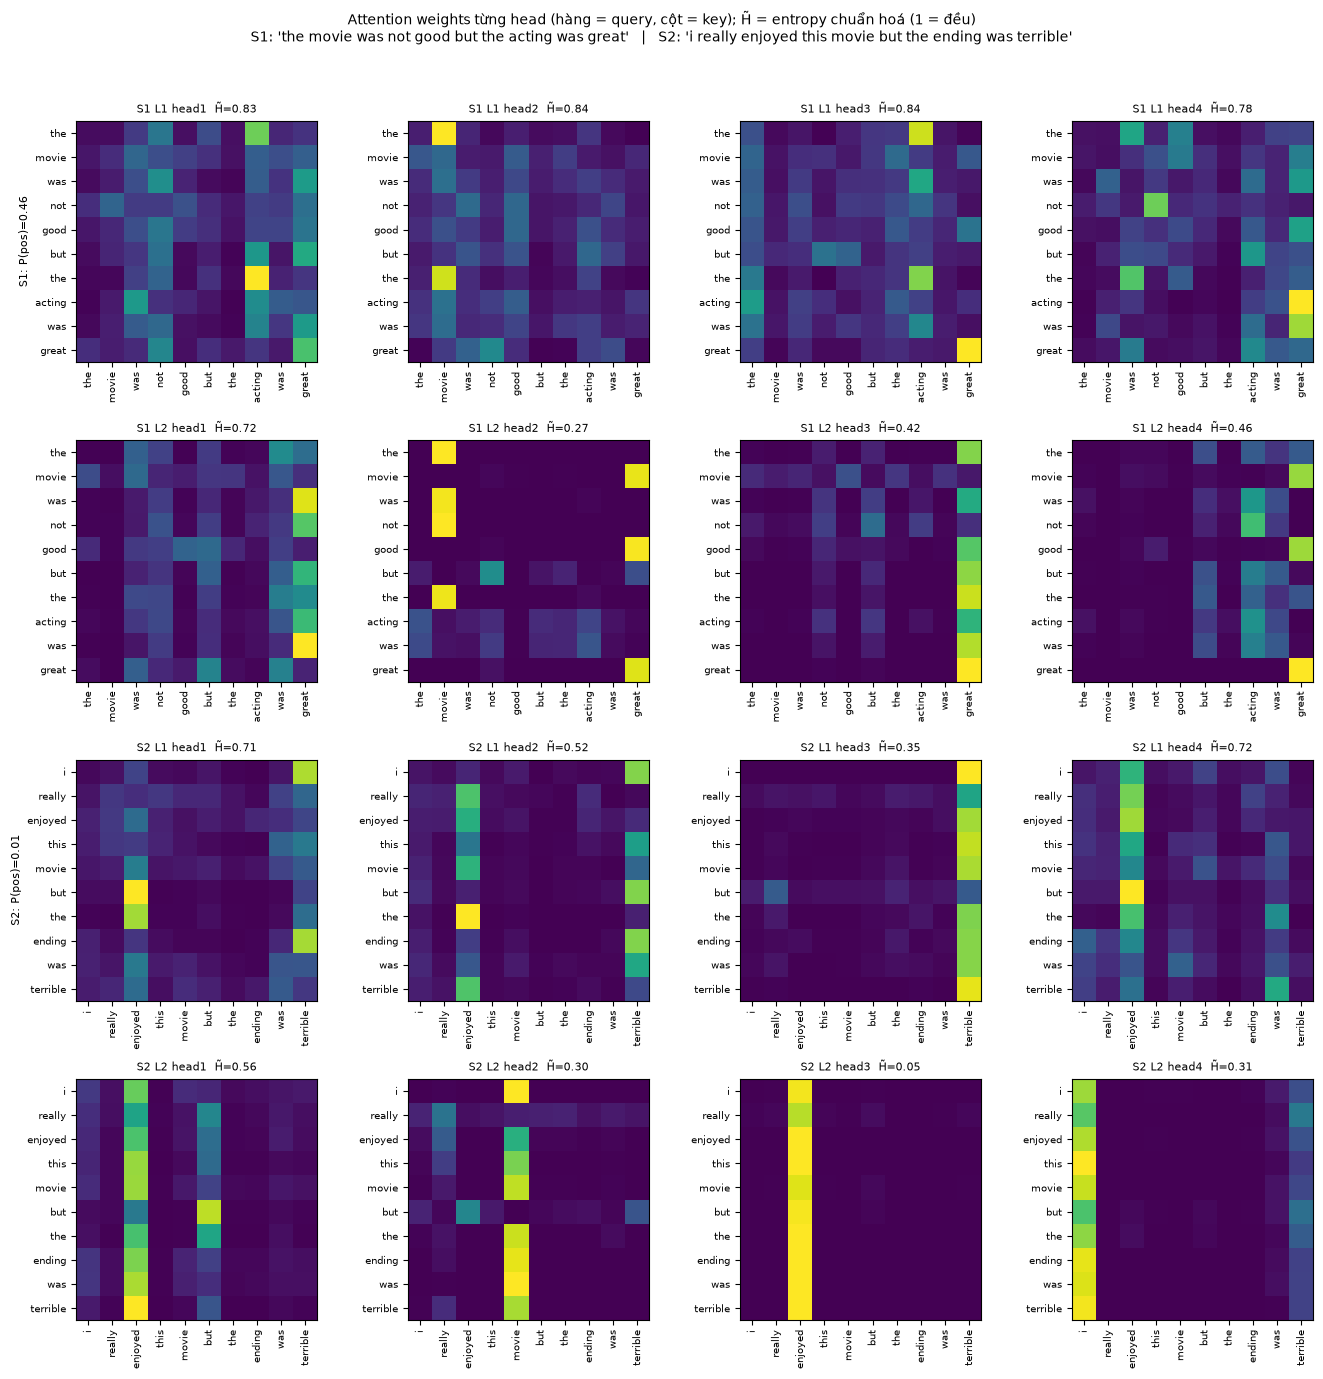

In [18]:
# attention_heads.png : 2 cau x 2 layer x 4 head
sents = ["the movie was not good but the acting was great", "i really enjoyed this movie but the ending was terrible"]
fig, axes = plt.subplots(2 * L, H, figsize=(3.4 * H, 3.5 * 2 * L))
for si, s in enumerate(sents):
    toks = sm.tokenize_text(s); ids = sm.encode_text(s, vocab); maps = get_attn(model, ids)
    with torch.no_grad(): pp = torch.sigmoid(model(torch.tensor([ids], device=dev))).item()
    for l in range(L):
        for h in range(H):
            ax = axes[si * L + l, h]; A = maps[l][h]
            ax.imshow(A, cmap="viridis", vmin=0, vmax=max(0.5, A.max())); ax.set_xticks(range(len(toks))); ax.set_yticks(range(len(toks)))
            ax.set_xticklabels(toks, rotation=90, fontsize=7); ax.set_yticklabels(toks, fontsize=7)
            ent = float((-(A * np.log(A + 1e-12)).sum(-1).mean()) / np.log(len(toks)))
            ax.set_title(f"S{si + 1} L{l + 1} head{h + 1}  H̃={ent:.2f}", fontsize=8)
    axes[si * L, 0].set_ylabel(f"S{si + 1}: P(pos)={pp:.2f}", fontsize=8)
fig.suptitle("Attention weights từng head (hàng = query, cột = key); H̃ = entropy chuẩn hoá (1 = đều)\nS1: '" + sents[0] + "'   |   S2: '" + sents[1] + "'", fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.savefig(LAB07 / "attention_heads.png", dpi=130); plt.show()

### Trả lời câu hỏi: Multi-head attention có thực sự tạo ra các attention patterns khác nhau trong experiment của bạn không?
Mô hình 4 head, 2 layer, 500 review test (số liệu ở cell thống kê phía trên; hình ở trên):

| layer | H̃ (entropy chuẩn hoá) 4 head | cos giữa các head | zero 1 head: giảm acc val (điểm %) |
|---|---|---|---|
| 1 | 0.84 / 0.83 / 0.83 / 0.77 | 0.203–0.253 | 0.76 / 0.76 / 0.71 / 0.40 |
| 2 | 0.68 / 0.57 / 0.54 / 0.39 | 0.061–0.175 | −0.09 / 0.11 / 0.28 / 0.10 |

**Multi-head có tạo pattern khác nhau thật không?** Có, trong thí nghiệm này: các attention map không giống nhau (cos ≤ 0.25 ở layer 1, ≤ 0.175 ở layer 2). Layer 1 phân tán hơn (H̃ ≈ 0.8); các head layer 2 tập trung hơn, nhiều head dồn gần hết query vào **một cột key** (vd. S2 layer 2 head 3: hầu hết query → "enjoyed", H̃ = 0.05). **Head thừa?** Bỏ riêng một head layer 2 gần như không đổi val acc (−0.09…0.28 điểm; val có 7,904 mẫu) → riêng lẻ gần như thừa; nhưng không phân biệt được "thừa thật" với "residual bù" (chưa ablate đồng thời nhiều head). Không gán nhãn syntax/semantics cho head vì không có bằng chứng.

## 13. Application — raw text → tokenizer → ids → model → xác suất

In [19]:
app_model = RUNS[("tf_h4_mean", SEED)]["model"].eval()
def predict_text(text, m=app_model, T=MAX_LEN):
    tokens = sm.tokenize_text(text)                          # raw text -> tokens
    ids = sm.encode_text(text, vocab)                        # tokens -> ids (UNK=1)
    padded, n = sm.pad_sequence(ids, T)                      # keep_first + PAD=0
    with torch.no_grad(): p = torch.sigmoid(m(torch.tensor([padded], device=dev))).item()
    return dict(n_tokens=len(tokens), n_unk=sum(i == 1 for i in ids), truncated=len(tokens) > T, label="Positive" if p >= 0.5 else "Negative", p_pos=p, p_neg=1 - p)
long_review = ("I went into this film with fairly high hopes because the trailer looked gorgeous and the cinematography in the first half hour really is beautiful. "
    "The opening scenes in the harbour town are shot with a warm, patient eye, the costumes are lovely and the score sets a pleasant mood. The story follows a retired sailor "
    "who returns to his village to settle the estate of his late brother, and for a while the premise seems to promise something thoughtful and moving. "
    "The supporting cast is charming and a couple of the early dialogue scenes are genuinely well written. However, after the first hour the picture loses all of its momentum. "
    "Subplots are introduced and then abandoned without any explanation, characters make decisions that no sensible person would make, and the long middle section drags "
    "on with repetitive conversations that go nowhere. By the time the final act arrives I had stopped caring about anybody on screen. The ending is predictable, clumsy "
    "and completely unearned. Overall this was a boring, disappointing waste of two hours and I cannot recommend it to anyone.")
examples = [("short", "I really enjoyed this movie."), ("short", "Terrible film, a complete waste of time."),
            ("long (verdict at the end)", long_review),
            ("negation", "This movie was not good at all."), ("negation", "I did not hate it; the film is not bad."),
            ("contrast", "The acting was great, but the story was boring and the ending was a disaster."), ("contrast", "At first it looked dull, but it turned into a wonderful film."),
            ("ambiguous", "It was okay, I guess."), ("ambiguous", "Some scenes were brilliant and others were awful.")]
rows = []
for cat, text in examples:
    r = predict_text(text); rows.append(dict(type=cat, text=(text if len(text) < 80 else text[:77] + "..."), **r))
    add_result("app_demo", cat, None, None, None, text=text, **r)
APP_DF = pd.DataFrame(rows); pd.set_option("display.width", 250, "display.max_colwidth", 85)
print(APP_DF.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
# kiem tra tinh nhat quan voi batch pipeline: cung cau, T=128 ->  model(ids) giong nhau

                     type                                                                             text  n_tokens  n_unk  truncated    label  p_pos  p_neg
                    short                                                     I really enjoyed this movie.         5      0      False Positive 0.9948 0.0052
                    short                                         Terrible film, a complete waste of time.         7      0      False Negative 0.0026 0.9974
long (verdict at the end) I went into this film with fairly high hopes because the trailer looked gorge...       182      1       True Negative 0.2318 0.7682
                 negation                                                  This movie was not good at all.         7      0      False Negative 0.0132 0.9868
                 negation                                          I did not hate it; the film is not bad.        10      0      False Negative 0.0060 0.9940
                 contrast    The acting was great, b

### Trả lời câu hỏi: Pipeline dự đoán thế nào với câu ngắn, dài, negation, contrast và ambiguous sentiment?
Pipeline: raw text → `sm.tokenize_text` → `encode_text` (UNK = 1) → `pad_sequence` (keep-first, PAD = 0) → model → sigmoid. Kết quả (bảng trên): câu ngắn đúng và rất chắc (0.9948 / 0.0026); review dài (182 token, 54 token cuối bị cắt) → Negative, P(pos) = 0.2318 (khớp kết luận tiêu cực của review); "not good at all" → Negative (đúng); **"I did not hate it; the film is not bad." → Negative, P(pos) = 0.0060 (nhiều khả năng sai)**; contrast "acting great, but story boring…" → Negative (hợp lý); **"At first it looked dull, but it turned into a wonderful film." → Negative, P(pos) = 0.0322 (sai)**; ambiguous: "It was okay, I guess." → Negative với P(pos) = 0.0038 (rất tự tin dù mơ hồ), "Some scenes were brilliant and others were awful." → 0.3165. 9 câu, 1 mô hình, 1 seed — chỉ là minh hoạ, chưa đủ kết luận về negation/contrast nói chung.

## 14. Error analysis — 3 đúng + 3 sai, chọn ngẫu nhiên có seed (không cherry-pick)

In [20]:
from collections import Counter
res = RUNS[("tf_h4_mean", SEED)]["test"]; res_l = RUNS[("lstm", SEED)]["test"]
y, p, pr = res["true_labels"], res["predictions"], res["probabilities"]
rng = np.random.RandomState(SEED)
tp, tn = np.where((y == 1) & (p == 1))[0], np.where((y == 0) & (p == 0))[0]
fp, fn = np.where((y == 0) & (p == 1))[0], np.where((y == 1) & (p == 0))[0]
def pick(pools):
    chosen = []
    for pool in pools:
        while True:
            c = int(rng.choice(pool))
            if c not in chosen: chosen.append(c); break
    return chosen
correct_sel = pick([tp, tn, np.concatenate([tp, tn])]); wrong_sel = pick([fp, fn, np.concatenate([fp, fn])])
print("test errors: FP=%d FN=%d (tong sai=%d / %d)" % (len(fp), len(fn), len(fp) + len(fn), len(y)))

# tu dien phan cuc (data-driven) tu Logistic Regression BoW tren TRAIN — chi de kiem tra 'token quan trong' co duoc attend khong
cv = CountVectorizer(tokenizer=sm.tokenize_text, lowercase=False, token_pattern=None, binary=True, max_features=20000)
Xtr = cv.fit_transform(train_df["text"]); lr_ = LogisticRegression(C=0.5, max_iter=2000).fit(Xtr, labels["train"])
coef = dict(zip(cv.get_feature_names_out(), lr_.coef_[0])); polar = dict(sorted(coef.items(), key=lambda kv: -abs(kv[1]))[:300])
print("BoW-LR test acc (tham chieu): %.4f" % lr_.score(cv.transform(test_df["text"]), labels["test"]))
NEG = {"not", "no", "never", "n't", "nothing", "none", "neither", "nor", "hardly", "cannot", "cant", "dont", "didnt", "wasnt", "isnt", "doesnt", "couldnt"}
CONTRAST = {"but", "however", "although", "though", "yet", "while", "despite", "nevertheless"}
@torch.no_grad()
def last_attn(ids):
    maps = get_attn(model, ids); return [a.mean(0).mean(0) * a.shape[-1] for a in maps]       # 'attention received' tuong doi, 1 = deu

def describe(i, tag):
    text, ids = test_df["text"].iloc[i], enc["test"][i]; toks = sm.tokenize_text(text)[:MAX_LEN]; n = len(ids)
    recv = last_attn(ids)
    seen_polar = sorted({t for t in toks if t in polar}, key=lambda t: -abs(polar[t]))[:6]
    rank_pct = lambda r, t: float(np.mean(r <= r[toks.index(t)]) * 100)
    top_att = [toks[j] for j in np.argsort(-recv[-1])[:8]]
    print("=" * 110); print(f"[{tag}] test idx {i} | true={'pos' if y[i] else 'neg'} | transformer P(pos)={pr[i]:.3f} | lstm P(pos)={res_l['probabilities'][i]:.3f}")
    print(f"tokens={n} truncated={n > MAX_LEN} | negation_words={sum(t in NEG for t in toks)} contrast_words={sum(t in CONTRAST for t in toks)} | UNK={sum(t == 1 for t in ids)} | 'br' tags={toks.count('br')}")
    all_toks = sm.tokenize_text(text)
    p_full = float(lr_.predict_proba(cv.transform([text]))[0, 1]); p_seen = float(lr_.predict_proba(cv.transform([" ".join(all_toks[:MAX_LEN])]))[0, 1])
    print(f"BoW-LR tham chieu: P(pos | toan van)={p_full:.3f} vs P(pos | chi {MAX_LEN} token dau)={p_seen:.3f}")
    print("MODEL THAY (128 token dau):", " ".join(toks))
    if n > MAX_LEN: print("PHAN BI CAT (cuoi review):", " ".join(all_toks[-45:]))
    print("polar tokens trong 128 token dau (tu LR: token, he so, percentile attention-received layer1, layer2):",
          [(t, round(float(polar[t]), 2), round(rank_pct(recv[0], t)), round(rank_pct(recv[1], t))) for t in seen_polar])
    print("top-8 token duoc attend (layer 2, trung binh head & query):", top_att)
    return dict(idx=i, tag=tag, true=int(y[i]), p_tf=float(pr[i]), p_lstm=float(res_l["probabilities"][i]), n_tokens=n, truncated=n > MAX_LEN,
                bow_lr_p_full=p_full, bow_lr_p_first128=p_seen, top_attended=top_att)
EVID = [describe(i, "CORRECT") for i in correct_sel] + [describe(i, "WRONG") for i in wrong_sel]
for e in EVID: add_result("error_analysis_sample", f"{e['tag']} idx={e['idx']}", **e)

# thong ke toan cuc: token phan cuc co duoc attend nhieu hon token con lai? (500 doc cua Exp 3)
rel_p, rel_o = [[], []], [[], []]
for i in sample_idx:
    toks = sm.tokenize_text(test_df["text"].iloc[i])[:MAX_LEN]; rc = last_attn(enc["test"][i])
    for l in range(2):
        for t, v in zip(toks, rc[l]): (rel_p if t in polar else rel_o)[l].append(v)
corpus_att = {f"layer{l + 1}": dict(polar_mean_rel=float(np.mean(rel_p[l])), other_mean_rel=float(np.mean(rel_o[l])), n_polar=len(rel_p[l])) for l in range(2)}
print("\nattention-received tuong doi (1 = deu), token phan cuc vs con lai:", corpus_att)
add_result("error_analysis_corpus_attention", "polar vs other tokens (500 test docs)", **corpus_att)
# thong ke loi theo do dai / cat cut
lens_test = np.array([len(s) for s in enc["test"]]); wrong = (y != p)
for name, mask in (("<=128 token (khong cat)", lens_test <= MAX_LEN), (">128 token (bi cat)", lens_test > MAX_LEN)):
    print(f"{name}: n={mask.sum()} error_rate={wrong[mask].mean():.4f}")
    add_result("error_analysis_by_length", name, n=int(mask.sum()), error_rate=float(wrong[mask].mean()))
negtxt = np.array([any(t in NEG for t in sm.tokenize_text(t_)) for t_ in test_df["text"]]); cont = np.array([any(t in CONTRAST for t in sm.tokenize_text(t_)) for t_ in test_df["text"]])
for name, mask in (("co negation word", negtxt), ("co contrast word", cont), ("khong negation/contrast", ~negtxt & ~cont)):
    print(f"{name}: n={mask.sum()} error_rate={wrong[mask].mean():.4f}"); add_result("error_analysis_by_feature", name, n=int(mask.sum()), error_rate=float(wrong[mask].mean()))

test errors: FP=709 FN=909 (tong sai=1618 / 10000)


BoW-LR test acc (tham chieu): 0.8850
[CORRECT] test idx 7811 | true=pos | transformer P(pos)=0.739 | lstm P(pos)=0.951
tokens=463 truncated=True | negation_words=4 contrast_words=2 | UNK=9 | 'br' tags=4
BoW-LR tham chieu: P(pos | toan van)=0.995 vs P(pos | chi 128 token dau)=0.926
MODEL THAY (128 token dau): i had never read any of sarah waters novels or watched tipping the velvet i only heard about fingersmith when i was flipping through the l word websites the storyline of fingersmith interested me yet i passed it away thinking lesbian in victorian period that never ends well i have enough of those lesbo series and movies that go no where br br however during christmas my local dvd store gave fingersmith a discount i brought the dvd and my life has never been more colourful br br this mini series deserves to be cherished and praised the acting is so great that i call it rare sally hawkins elaine cassidy rupert evans imelda staunton and many more that i can't name all brought light an


attention-received tuong doi (1 = deu), token phan cuc vs con lai: {'layer1': {'polar_mean_rel': 3.3551697731018066, 'other_mean_rel': 0.946684718132019, 'n_polar': 1336}, 'layer2': {'polar_mean_rel': 5.317008018493652, 'other_mean_rel': 0.9022735357284546, 'n_polar': 1336}}
<=128 token (khong cat): n=2529 error_rate=0.1194
>128 token (bi cat): n=7471 error_rate=0.1761


co negation word: n=7861 error_rate=0.1702
co contrast word: n=8193 error_rate=0.1732
khong negation/contrast: n=718 error_rate=0.0933


### Trả lời câu hỏi: Các token quan trọng có xuất hiện trong attention pattern hay không — và attention có phải là explanation?
Chi tiết 3 mẫu đúng + 3 mẫu sai trong `error_analysis.md`. Tóm tắt từ output: sai 1,618/10,000 (FP 709, FN 909); review ≤ 128 token sai 11.94% so với 17.61% ở review bị cắt (>128 token); token "phân cực" nhận attention tương đối 3.36× (layer 1) và 5.32× (layer 2) so với trung bình đều, token còn lại 0.95× / 0.90×. **Attention ≠ explanation:** đây là tương quan của phân phối trọng số, không chứng minh mô hình *dùng* các token đó (các mẫu sai vẫn attend đúng token phân cực, vd. W3: perfect/great/disappointing đều được attend mạnh nhưng dự đoán sai) — phân biệt *model behavior* với *human interpretation*; muốn kết luận nguyên nhân phải can thiệp (xoá/thay token).

## 15. Lưu `results.csv`

In [21]:
out = pd.DataFrame(RESULTS, columns=["experiment", "config", "params", "train_time_s", "accuracy", "precision", "recall", "f1", "extra"])
out.to_csv(LAB07 / "results.csv", index=False, encoding="utf-8")
print(len(out), "rows ->", LAB07 / "results.csv"); print(out.groupby("experiment").size().to_string())

71 rows -> D:\Study\Semester 7\NLP\Lab07\results.csv
experiment
app_demo                           9
calc                               2
error_analysis_by_feature          3
error_analysis_by_length           2
error_analysis_corpus_attention    1
error_analysis_sample              6
exp1_permutation                   8
exp1b_pe_ablation                  2
exp2_heads                         4
exp3_head_ablation                 8
exp3_head_diversity                8
exp4_lstm_vs_transformer           2
exp5_seq_length                    8
exp5b_benchmark                    5
exp6_pooling                       2
unit_test                          1


## Trả lời câu hỏi: Từ LAB 01 tới LAB 07, mỗi bước đã giải quyết limitation nào của bước trước?
```
TF-IDF
  ↓ Limitation: vector thưa, chiều cao; túi từ — mất thứ tự; "good" và "great" là hai chiều không liên quan
Word2Vec (trung bình)
  ↓ Limitation: một vector tĩnh cho mỗi từ (không theo ngữ cảnh, đa nghĩa); trung bình vẫn là túi từ
LSTM
  ↓ Limitation: tuần tự theo timestep (không song song theo T); thông tin qua hidden state cố định; phụ thuộc xa khó
    (LAB 05, GRU: F1 0.7659 → 0.8433 khi length 50 → 200)
Attention
  ↓ Limitation: nếu chỉ thêm lên RNN thì backbone vẫn tuần tự; attention không biết thứ tự (cần PE); chi phí O(T²)
Transformer
  ↓ Remaining limitation: O(T²) thời gian/bộ nhớ (T=1024: 2,184 MB so với LSTM 532 MB), độ dài tối đa cố định;
    train từ đầu cần nhiều dữ liệu (acc 0.835 < TF-IDF 0.8958); attention ≠ giải thích → LAB 08: pretraining/BERT
```

## Kiểm chứng 6 prediction ban đầu (từ `prediction.md`, không sửa)

| # | Dự đoán (từ `prediction.md`) | Kết quả (experiment) | Đúng/Sai | Giải thích |
|---|---|---|---|---|
| 1 | **Có** — attention là phép nhân ma trận cho mọi cặp cùng lúc; RNN đợi h_{t-1} (90%) | Benchmark T=128: Tf 16.7 vs LSTM 25.0 ms; T=256: 17.1 vs 39.4 ms; nhưng T=1024: 152.9 vs 135.1 ms; train thực Tf chậm hơn LSTM ở mọi T (vd 63.7 vs 60.9 s) | **Đúng** (về tính song song) | Step time Tf gần phẳng khi T gấp đôi, LSTM tăng ×1.6; "song song hơn" ≠ "train nhanh hơn" (cuDNN LSTM, O(T²)). |
| 2 | **Không** — permutation-equivariant (90%) | Exp 1: không PE, S2 là hoán vị hàng của S1 (lệch ≤ 2.4e-7) | **Đúng** | Khớp lý do đã nêu. |
| 3 | **Không** — output chỉ hoán vị, sau mean pooling cùng vector (90%) | Không PE: pooled lệch 6e-8…1.8e-7; có PE: 0.157–0.250 | **Đúng** | Khớp cả chi tiết "chỉ bị hoán vị". |
| 4 | **Không bắt buộc**; thường khác, có thể có head thừa (80%) | cos giữa head 0.203–0.253 (L1), 0.061–0.175 (L2); zero head L2: −0.09…0.28 điểm | **Đúng** (head thừa: ủng hộ một phần) | Chưa phân biệt "thừa thật" với "residual bù". |
| 5 | **Không** — d_k giảm, tham số gần như không đổi (85%) | acc 3 seeds 0.8356 / 0.8321 / 0.8353 / 0.8331; params đều 4,105,089 | **Đúng** | Tham số không đổi *chính xác*; chênh lệch trong nhiễu. |
| 6 | **Không** — O(T²); T dài thì bộ nhớ tăng nhanh (80%) | Tf không nhanh hơn ở T nào khi train thực; benchmark chậm hơn ở T=1024; peak 2,184 vs 532 MB | **Đúng** | Phần "T ngắn thì overhead nhỏ" không khớp hẳn: ở T=32 Tf vẫn chậm hơn LSTM (37.2 vs 31.5 s). |